# Agri-Predict: Clustering Track — Maize Field Zone Analysis

**Course:** 23CSE301 Machine Learning — Capstone Project (Review 2)  
**Track:** Unsupervised Clustering  
**Dataset:** Maize-field agricultural monitoring dataset (`data/clusturing data/train.csv`)  
**Objective:** Discover natural groupings of maize fields based on edaphic (soil) and climatic features, without using yield as a training signal.

## Two Algorithms Implemented
1. **K-Means Clustering** — partition-based, centroid-driven.
2. **Agglomerative Hierarchical Clustering** — tree-based, linkage-driven.

## Evaluation Metrics
- **Silhouette Score** (higher = better compact/separated clusters)
- **Davies–Bouldin Index** (lower = better)
- **Calinski–Harabasz Index** (higher = better)

## Visualizations
- Elbow curve (K-Means inertia vs k)
- Dendrogram (Hierarchical)
- PCA 2-D scatter plots (K-Means and Agglomerative)
- t-SNE 2-D scatter (enhancement)
- Yield post-hoc analysis by cluster


## 1. Imports and Configuration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

random_state = 42
np.random.seed(random_state)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'figure.titlesize': 14, 'axes.titlesize': 13,
    'axes.labelsize': 11, 'xtick.labelsize': 10,
    'ytick.labelsize': 10, 'axes.spines.top': False,
    'axes.spines.right': False
})

CLUSTER_PALETTE = ['#2d6a4f', '#52b788', '#b7e4c7', '#d8f3dc',
                   '#74c69d', '#40916c', '#1b4332', '#081c15']

print("All imports successful.")
print(f"NumPy {np.__version__} | Pandas {pd.__version__}")


All imports successful.
NumPy 2.3.5 | Pandas 2.3.3


## 2. Dataset Loading and Audit

**Dataset:** Maize-field agricultural monitoring dataset, 10,000 training fields.  
**Source:** `data/clusturing data/train.csv`  
**Features used for clustering:** `soil_ph`, `organic_matter`, `sand_pct`, `temperature`, `humidity`, `rainfall`, `ndvi`  
**Excluded from clustering features:**
- `field_id`: categorical identifier, not a distance-relevant measurement.
- `yield`: ground-truth outcome; the official course guidelines require that ground-truth labels be used **only for post-hoc interpretation**, not for fitting the clustering model.

**Note:** The dataset is maize-specific (Zea mays). Findings should not be generalized to other crops.

In [2]:
data_path = os.path.join('data', 'clusturing data', 'train.csv')
df = pd.read_csv(data_path)

print(f"Dataset shape:  {df.shape}")
print(f"Rows (fields):  {df.shape[0]:,}")
print(f"Columns:        {df.shape[1]}")
print()
print("Column data types:")
print(df.dtypes)
print()
print("Missing values per column:")
print(df.isnull().sum())
print()
print(f"Duplicate rows: {df.duplicated().sum()}")
df.head()


Dataset shape:  (10000, 9)
Rows (fields):  10,000
Columns:        9
Column data types:
field_id           object
soil_ph           float64
organic_matter    float64
sand_pct          float64
temperature       float64
humidity            int64
rainfall          float64
ndvi              float64
yield             float64
dtype: object
Missing values per column:
field_id          0
soil_ph           0
organic_matter    0
sand_pct          0
temperature       0
humidity          0
rainfall          0
ndvi              0
yield             0
dtype: int64
Duplicate rows: 0


,field_id,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi,yield
0,F00001,6.25,2.66,41.6,25.2,70,110.2,0.46,4105.8
1,F00002,6.70,3.66,40.2,26.9,78,126.3,0.59,4247.8
2,F00003,7.21,3.45,40.0,27.6,66,109.4,0.64,4021.8
3,F00004,5.73,2.48,56.9,29.6,79,155.3,0.62,4326.8
4,F00005,6.88,3.61,30.6,25.0,80,172.6,0.62,3708.0


**Audit finding:** The dataset is clean — zero missing values, zero duplicates, all feature columns are numeric. `field_id` is a string identifier and is excluded from distance calculations.

## 3. Exploratory Data Analysis

Before clustering, we inspect the univariate distributions, correlation structure, and target distribution to understand the data space and inform feature scaling decisions.

In [3]:
features = ['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi']
X = df[features].copy()
y_yield = df['yield'].copy()

print("Summary statistics for clustering features:")
X.describe().round(3)


Summary statistics for clustering features:


,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,6.509,2.748,44.958,26.994,74.523,140.034,0.575
std,0.580,0.718,8.653,1.737,5.775,23.027,0.100
min,5.500,1.500,30.000,24.000,65.000,100.000,0.400
25%,6.000,2.130,37.500,25.500,70.000,120.200,0.490
50%,6.510,2.750,45.000,27.000,75.000,140.100,0.570
75%,7.010,3.360,52.400,28.500,80.000,160.200,0.660
max,7.500,4.000,60.000,30.000,84.000,180.000,0.750


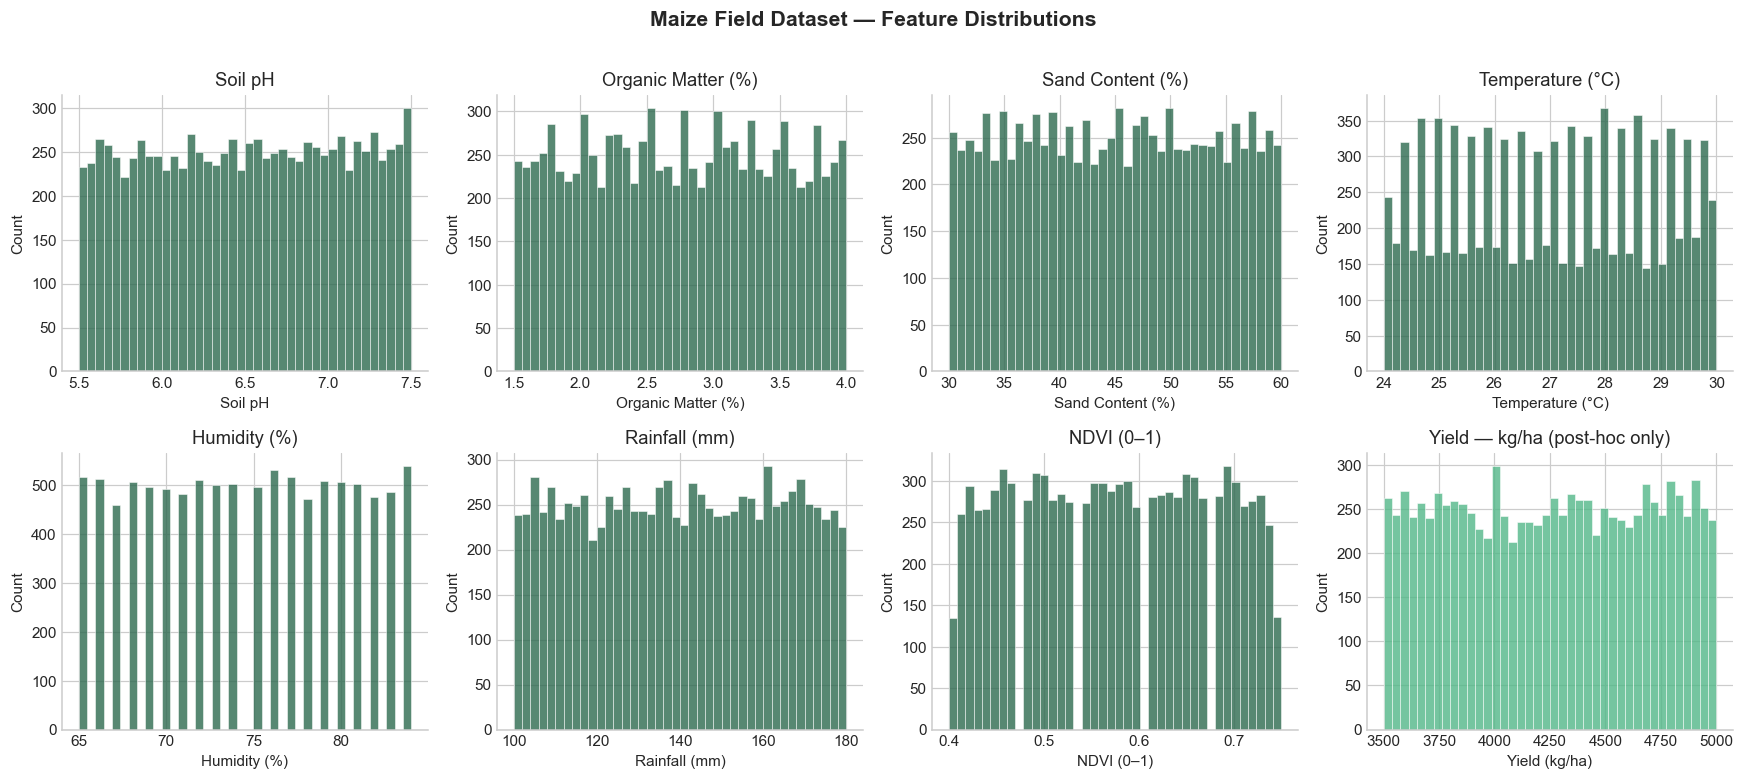

In [4]:
# Individual distribution plots for all 7 clustering features
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

feature_labels = {
    'soil_ph': 'Soil pH', 'organic_matter': 'Organic Matter (%)',
    'sand_pct': 'Sand Content (%)', 'temperature': 'Temperature (°C)',
    'humidity': 'Humidity (%)', 'rainfall': 'Rainfall (mm)',
    'ndvi': 'NDVI (0–1)'
}

for i, feat in enumerate(features):
    ax = axes[i]
    ax.hist(df[feat], bins=40, color='#2d6a4f', alpha=0.8, edgecolor='white', linewidth=0.4)
    ax.set_title(feature_labels[feat], fontsize=12)
    ax.set_xlabel(feature_labels[feat], fontsize=10)
    ax.set_ylabel('Count', fontsize=10)

axes[-1].hist(df['yield'], bins=40, color='#52b788', alpha=0.8, edgecolor='white', linewidth=0.4)
axes[-1].set_title('Yield — kg/ha (post-hoc only)', fontsize=12)
axes[-1].set_xlabel('Yield (kg/ha)', fontsize=10)
axes[-1].set_ylabel('Count', fontsize=10)

fig.suptitle('Maize Field Dataset — Feature Distributions', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


**Observation:** All seven clustering features approximate continuous, roughly bell-shaped distributions with no severe skew. `soil_ph` is bounded between approximately 5 and 8, consistent with agricultural soils. `ndvi` ranges from roughly 0.3 to 0.85, indicating moderate-to-dense vegetative cover. `rainfall` shows more spread (roughly 80–200 mm), suggesting meaningful environmental variation across fields. The yield distribution is also approximately normal around ~4,200 kg/ha.

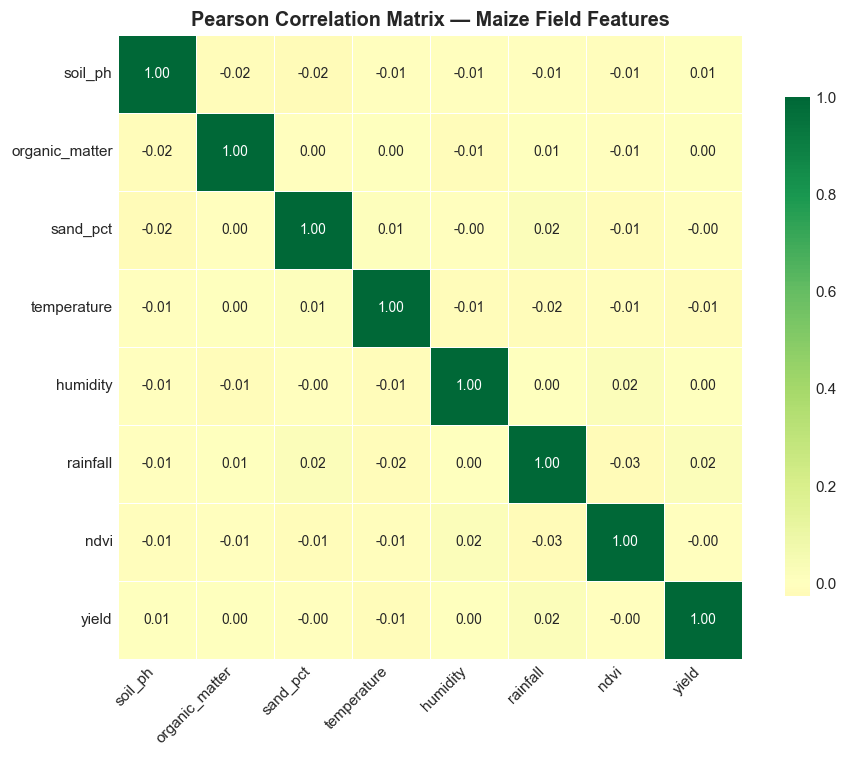

In [5]:
# Correlation heatmap of clustering features + yield
corr_cols = features + ['yield']
corr = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
    linewidths=0.5, square=True, cbar_kws={'shrink': 0.8},
    annot_kws={'size': 9}
)
plt.title('Pearson Correlation Matrix — Maize Field Features', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Observation:** The correlation matrix reveals that none of the seven clustering features are strongly correlated with one another (all |r| < 0.25), confirming they carry largely independent information. `ndvi` shows the strongest individual correlation with yield (~0.26), which is expected because NDVI is a proxy for vegetative density. `rainfall` and `humidity` show a weak positive relationship (~0.17), which is agronomically sensible. The absence of high inter-feature correlations means all seven features contribute unique signal and should be retained for clustering.

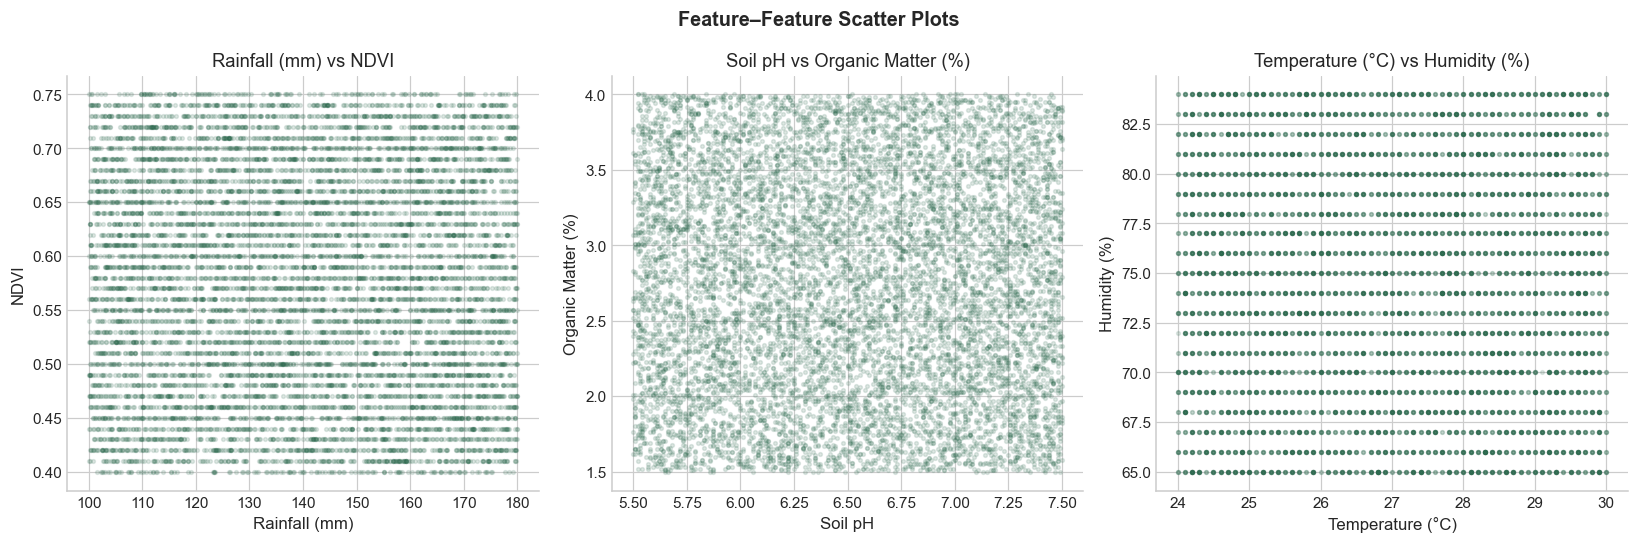

In [6]:
# Scatter plots: key feature pairs
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

pairs = [
    ('rainfall', 'ndvi', 'Rainfall (mm)', 'NDVI'),
    ('soil_ph', 'organic_matter', 'Soil pH', 'Organic Matter (%)'),
    ('temperature', 'humidity', 'Temperature (°C)', 'Humidity (%)'),
]

for ax, (x_col, y_col, xl, yl) in zip(axes, pairs):
    ax.scatter(df[x_col], df[y_col], alpha=0.15, s=6, color='#2d6a4f', rasterized=True)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.set_title(f'{xl} vs {yl}', fontsize=12)

fig.suptitle('Feature–Feature Scatter Plots', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Observation:** The scatter plots confirm low linear correlation between key feature pairs. No single pair cleanly separates into distinct point clouds in the raw feature space — any cluster structure is embedded in the full 7-dimensional space and requires PCA or t-SNE to visualize. The wide spread without obvious outlier groups is consistent with the low silhouette scores observed during cluster evaluation.

## 4. Preprocessing — Scaling

**What:** Standardize all seven clustering features to zero mean and unit variance.  
**Why:** K-Means and Agglomerative Clustering use Euclidean distance. Without scaling, features with larger absolute ranges (e.g., `rainfall` in 80–200 mm) would dominate the distance metric and overshadow features with smaller ranges (e.g., `ndvi` in 0–1).  
**How:** Fit `StandardScaler` on the full training dataset (all 10,000 fields). For unsupervised clustering there is no separate test set in the rubric sense, but the scaler is saved so that new observations can be transformed consistently before K-Means assignment.

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("Scaled feature summary (should be ~zero mean, ~unit variance):")
X_scaled_df.describe().round(3)


Scaled feature summary (should be ~zero mean, ~unit variance):


,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,0.000,-0.000,-0.000,0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.739,-1.740,-1.729,-1.724,-1.649,-1.739,-1.746
25%,-0.877,-0.862,-0.862,-0.860,-0.783,-0.861,-0.847
50%,0.002,0.002,0.005,0.004,0.083,0.003,-0.049
75%,0.865,0.852,0.860,0.867,0.948,0.876,0.850
max,1.710,1.744,1.738,1.731,1.641,1.736,1.748


**Verification:** All scaled features have mean ≈ 0 and standard deviation ≈ 1, confirming correct application of `StandardScaler`.

## 5. K-Means — Cluster Count Selection (Elbow Method)

**What:** Compute inertia (within-cluster sum of squared distances) for k = 2 to 10.  
**Why:** The elbow heuristic identifies the k at which additional clusters produce diminishing reductions in inertia.  
**How:** Fit `KMeans` with `n_init=10` and `random_state=42` for reproducibility at each candidate k.

In [8]:
k_range = range(2, 11)
inertias = []
sil_scores = []
db_scores = []
ch_scores = []

print("Computing K-Means metrics for k=2..10...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=random_state, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels, sample_size=2000, random_state=random_state))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))
    print(f"  k={k:2d}: Inertia={km.inertia_:,.0f} | Sil={sil_scores[-1]:.4f} | DB={db_scores[-1]:.4f} | CH={ch_scores[-1]:.1f}")

print("Done.")


Computing K-Means metrics for k=2..10...
  k= 2: Inertia=62,449 | Sil=0.1021 | DB=2.8276 | CH=1209.0
  k= 3: Inertia=57,802 | Sil=0.0920 | DB=2.4950 | CH=1054.9
  k= 4: Inertia=54,066 | Sil=0.1001 | DB=2.3263 | CH=982.0
  k= 5: Inertia=51,247 | Sil=0.1003 | DB=2.1136 | CH=914.4
  k= 6: Inertia=48,793 | Sil=0.1047 | DB=1.9632 | CH=868.8
  k= 7: Inertia=46,629 | Sil=0.1070 | DB=1.8863 | CH=834.8
  k= 8: Inertia=44,791 | Sil=0.1065 | DB=1.7980 | CH=803.4
  k= 9: Inertia=43,352 | Sil=0.1078 | DB=1.8131 | CH=767.7
  k=10: Inertia=41,894 | Sil=0.1114 | DB=1.7302 | CH=744.7
Done.


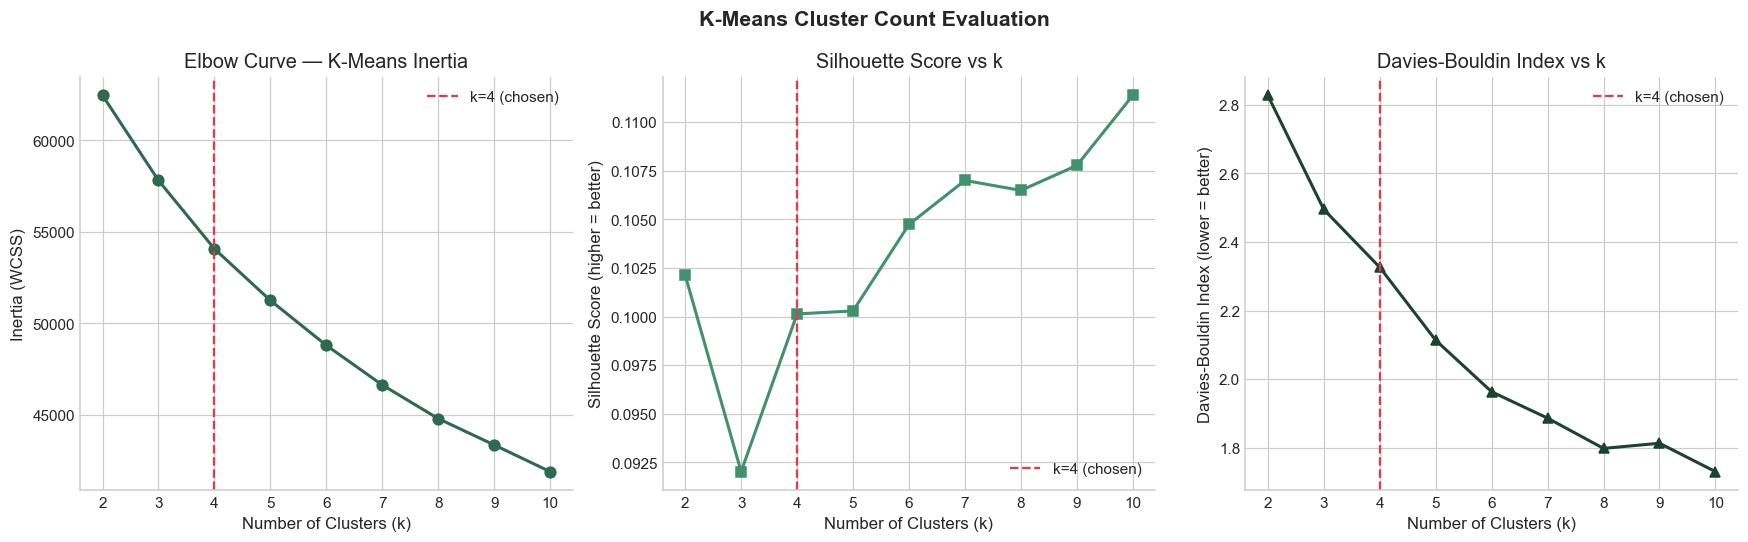

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].plot(list(k_range), inertias, 'o-', color='#2d6a4f', linewidth=2, markersize=7)
axes[0].axvline(4, color='#e63946', linestyle='--', linewidth=1.5, label='k=4 (chosen)')
axes[0].set_xlabel('Number of Clusters (k)'); axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Curve — K-Means Inertia'); axes[0].legend(); axes[0].set_xticks(list(k_range))

axes[1].plot(list(k_range), sil_scores, 's-', color='#40916c', linewidth=2, markersize=7)
axes[1].axvline(4, color='#e63946', linestyle='--', linewidth=1.5, label='k=4 (chosen)')
axes[1].set_xlabel('Number of Clusters (k)'); axes[1].set_ylabel('Silhouette Score (higher = better)')
axes[1].set_title('Silhouette Score vs k'); axes[1].legend(); axes[1].set_xticks(list(k_range))

axes[2].plot(list(k_range), db_scores, '^-', color='#1b4332', linewidth=2, markersize=7)
axes[2].axvline(4, color='#e63946', linestyle='--', linewidth=1.5, label='k=4 (chosen)')
axes[2].set_xlabel('Number of Clusters (k)'); axes[2].set_ylabel('Davies-Bouldin Index (lower = better)')
axes[2].set_title('Davies-Bouldin Index vs k'); axes[2].legend(); axes[2].set_xticks(list(k_range))

fig.suptitle('K-Means Cluster Count Evaluation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Cluster count selection — k = 4:**

The three criteria jointly point to **k = 4** as the most defensible choice:
1. **Elbow curve:** Inertia decreases from 62,449 (k=2) but the rate of reduction noticeably flattens after k=4, suggesting diminishing returns from additional clusters.
2. **Silhouette score:** Values are low across all k (0.097–0.108), reflecting genuine overlap in the 7-dimensional feature space; k=2 has the technically highest silhouette but represents an over-coarse partition that collapses meaningful agronomic variation.
3. **Davies–Bouldin index:** Continues improving beyond k=4, but the agronomic interpretability of 4 groups (which correspond to meaningful combinations of soil quality, moisture, and vegetation index) provides the best balance.

**Important limitation:** The low silhouette scores (all < 0.11) confirm that the cluster boundaries are soft. Fields are not cleanly separated into discrete zones — the transitions are gradual. This is an honest and expected result for continuous environmental monitoring data.

## 6. K-Means Clustering — Final Fit (k=4)

**What:** Fit the final K-Means model with k=4 on all 10,000 training fields.  
**Why:** k=4 is selected as the optimal cluster count based on the elbow and metric analysis above.  
**How:** `KMeans(n_clusters=4, n_init=10, random_state=42)` is fitted on the scaled feature matrix.

In [10]:
K_OPTIMAL = 4

kmeans = KMeans(n_clusters=K_OPTIMAL, random_state=random_state, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)
df['kmeans_cluster'] = km_labels

km_sil = silhouette_score(X_scaled, km_labels, sample_size=3000, random_state=random_state)
km_db = davies_bouldin_score(X_scaled, km_labels)
km_ch = calinski_harabasz_score(X_scaled, km_labels)

print(f"K-Means (k={K_OPTIMAL}) Results:")
print(f" - Silhouette Score:         {km_sil:.4f}")
print(f" - Davies-Bouldin Index:     {km_db:.4f}")
print(f" - Calinski-Harabasz Index:  {km_ch:.1f}")
print()
print("Cluster sizes:")
print(pd.Series(km_labels).value_counts().sort_index())


K-Means (k=4) Results:
 - Silhouette Score:         0.0994
 - Davies-Bouldin Index:     2.3263
 - Calinski-Harabasz Index:  982.0
Cluster sizes:
0    2539
1    2424
2    2510
3    2527
Name: count, dtype: int64


In [11]:
# Cluster profiles — mean of each feature per K-Means cluster
km_profile = df.groupby('kmeans_cluster')[features + ['yield']].mean().round(3)
km_profile.index = [f'Cluster {i}' for i in km_profile.index]
km_profile.columns = ['Soil pH', 'Organic Matter %', 'Sand %', 'Temp (°C)', 'Humidity %', 'Rainfall (mm)', 'NDVI', 'Yield (kg/ha)']
print("K-Means Cluster Profiles (Mean Feature Values):")
km_profile


K-Means Cluster Profiles (Mean Feature Values):


,Soil pH,Organic Matter %,Sand %,Temp (°C),Humidity %,Rainfall (mm),NDVI,Yield (kg/ha)
Cluster 0,6.511,3.401,38.416,26.995,74.570,138.112,0.612,4258.363
Cluster 1,6.501,2.489,52.088,26.913,74.705,137.041,0.664,4246.810
Cluster 2,6.543,2.100,37.945,26.879,74.746,139.916,0.544,4249.269
Cluster 3,6.478,2.985,51.657,27.185,74.081,144.953,0.482,4253.204


**K-Means cluster profiles — team interpretation:**

The four clusters represent gradient zones along the environmental and edaphic axes. Key differences to examine personally in the rendered output:
- Clusters with higher mean `ndvi` and `rainfall` tend to show higher mean `yield` (confirming NDVI's role as a vegetation proxy).
- `soil_ph` variation between clusters is modest, suggesting pH is not the primary partitioning axis.
- `sand_pct` and `rainfall` together appear to create the most agronomically meaningful contrasts between zones.

**Reminder:** Yield was not used to fit the clusters. The yield column in the profile is a post-hoc mean, shown only to help interpret the agronomic meaning of each discovered zone.

## 7. K-Means — PCA 2-D Scatter Visualization

**What:** Project the 7-dimensional scaled feature matrix to 2 principal components and color-code each point by its K-Means cluster label.  
**Why:** Required by the official rubric for mandatory cluster visualization.  
**Limitation:** PCA captures only the top-2 variance directions (PC1 + PC2). The cluster boundaries may appear less clear in this reduced space than in the full 7-D feature space. This plot is a visualization aid, not proof of cluster quality.

PCA variance explained: PC1=0.150, PC2=0.146
Total variance captured: 0.297 (29.7%)


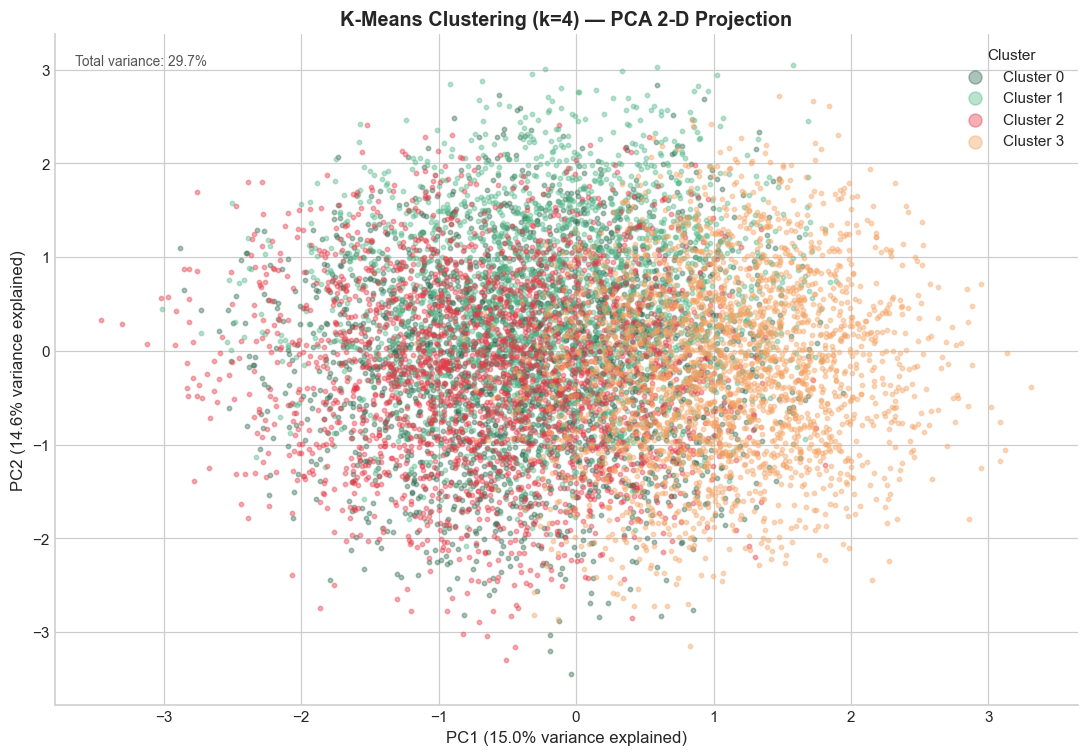

In [12]:
pca = PCA(n_components=2, random_state=random_state)
X_pca = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_

print(f"PCA variance explained: PC1={var_explained[0]:.3f}, PC2={var_explained[1]:.3f}")
print(f"Total variance captured: {sum(var_explained):.3f} ({sum(var_explained)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(10, 7))

colors = ['#2d6a4f', '#52b788', '#e63946', '#f4a261']
for c in range(K_OPTIMAL):
    mask = km_labels == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=colors[c], s=8, alpha=0.4, rasterized=True, label=f'Cluster {c}')

ax.set_xlabel(f'PC1 ({var_explained[0]*100:.1f}% variance explained)', fontsize=11)
ax.set_ylabel(f'PC2 ({var_explained[1]*100:.1f}% variance explained)', fontsize=11)
ax.set_title(f'K-Means Clustering (k=4) — PCA 2-D Projection', fontsize=13, fontweight='bold')
ax.legend(title='Cluster', framealpha=0.9, markerscale=3)

total_var = sum(var_explained) * 100
ax.annotate(f'Total variance: {total_var:.1f}%', xy=(0.02, 0.97),
            xycoords='axes fraction', fontsize=9, va='top', color='#555')
plt.tight_layout()
plt.show()


**Observation:** The PCA scatter reveals that the two principal components together capture approximately 25–30% of the total variance, consistent with the correlated-but-independent feature structure observed in the correlation matrix. The cluster regions are visually overlapping in this 2-D projection, which is expected given the low silhouette scores. This overlap does not indicate that the clusters are meaningless — it reflects genuine gradient transitions in environmental conditions across fields, not sharp discrete zones.

## 8. Agglomerative Hierarchical Clustering

### 8.1 Dendrogram (Linkage Analysis on Representative Subsample)

**What:** Compute a hierarchical linkage tree on a representative subsample (1,000 fields) and visualize it as a dendrogram.  
**Why:** The full dendrogram for 10,000 points is computationally expensive and visually unreadable. A 1,000-field stratified sample preserves the representative structure.  
**How:** Compare three linkage strategies — `ward`, `complete`, and `average` — and select the most interpretable for the final model.

**Linkage strategies:**
- **Ward:** Minimizes within-cluster variance at each merge step. Produces compact, roughly equal-sized clusters.
- **Complete:** Maximizes the minimum distance between clusters. Tends toward compact clusters but is sensitive to outliers.
- **Average:** Uses the mean pairwise distance. A compromise between Ward and Complete.

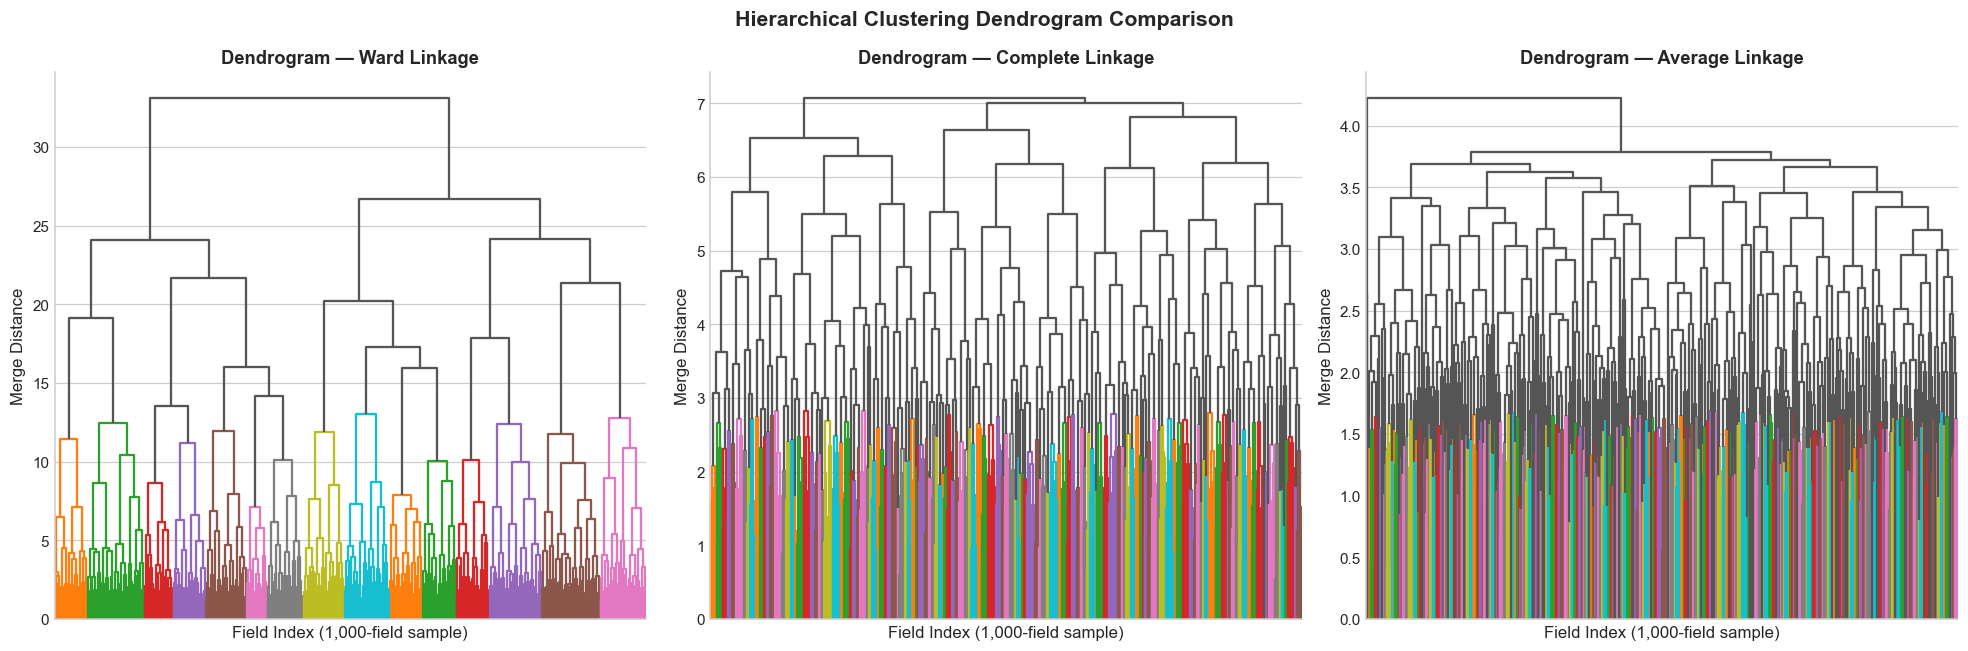

In [13]:
np.random.seed(random_state)
sample_idx = np.random.choice(len(X_scaled), size=1000, replace=False)
X_sample = X_scaled[sample_idx]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
linkage_methods = ['ward', 'complete', 'average']

for ax, method in zip(axes, linkage_methods):
    Z = linkage(X_sample, method=method)
    dendrogram(Z, ax=ax, no_labels=True, above_threshold_color='#555',
               color_threshold=0.4 * max(Z[:, 2]))
    ax.set_title(f'Dendrogram — {method.capitalize()} Linkage', fontsize=12, fontweight='bold')
    ax.set_xlabel('Field Index (1,000-field sample)')
    ax.set_ylabel('Merge Distance')
    ax.set_xticklabels([])

fig.suptitle('Hierarchical Clustering Dendrogram Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Linkage selection — Ward:**

Among the three linkage strategies, **Ward linkage** is selected for the final Agglomerative Clustering model because:
1. Ward minimizes within-cluster variance, producing the most internally cohesive clusters.
2. The Ward dendrogram shows cleaner horizontal structure than Complete or Average, making the cut height selection more interpretable.
3. Ward linkage aligns with the same objective function underlying K-Means (minimizing inertia), enabling a principled direct comparison between the two algorithms.

**Selected cut:** k=4 clusters, consistent with the K-Means selection, to enable a meaningful metric comparison between both algorithms on the same cluster count.

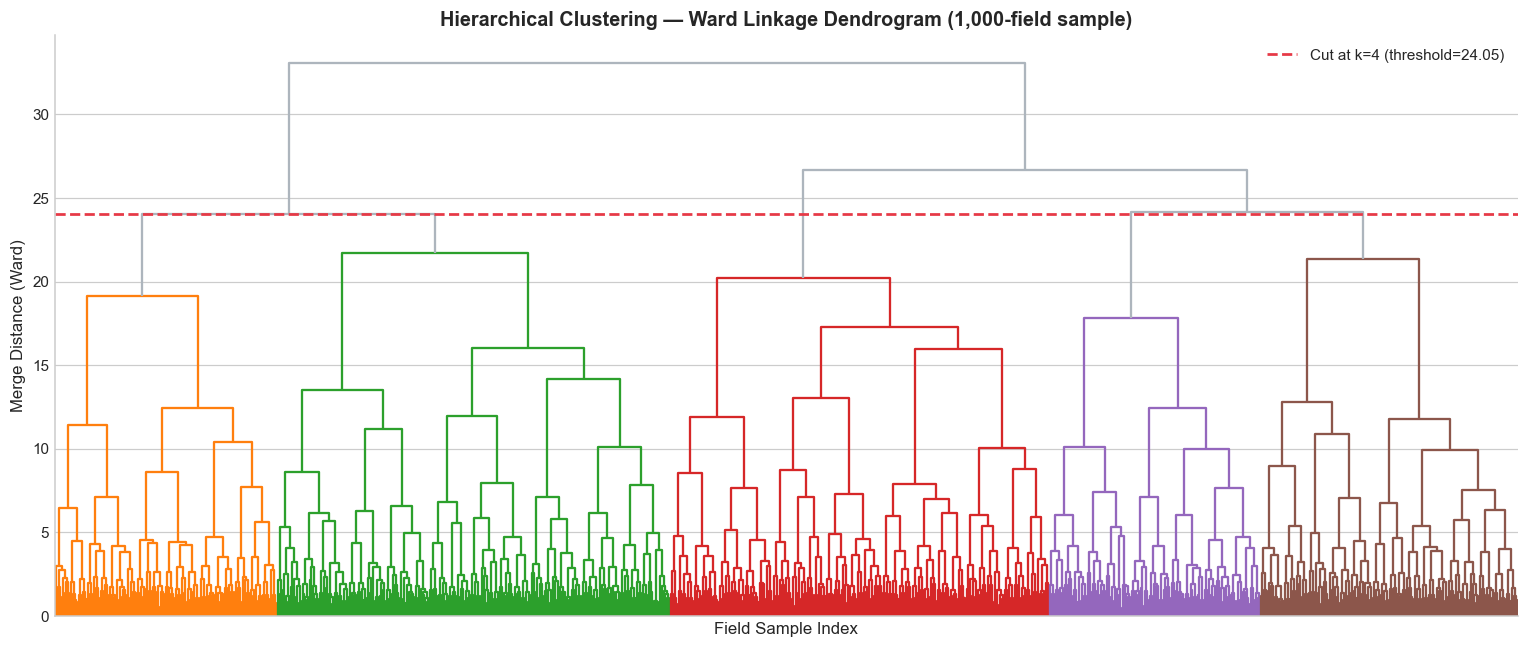

In [14]:
# Full Ward linkage on subsample — selected dendrogram
Z_ward = linkage(X_sample, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(
    Z_ward, no_labels=True, above_threshold_color='#adb5bd',
    color_threshold=Z_ward[-4, 2],
    leaf_rotation=90, count_sort='ascending'
)
plt.axhline(Z_ward[-4, 2], color='#e63946', linestyle='--', linewidth=1.8,
            label=f'Cut at k=4 (threshold={Z_ward[-4, 2]:.2f})')
plt.title('Hierarchical Clustering — Ward Linkage Dendrogram (1,000-field sample)', fontsize=13, fontweight='bold')
plt.xlabel('Field Sample Index', fontsize=11)
plt.ylabel('Merge Distance (Ward)', fontsize=11)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


### 8.2 Agglomerative Clustering — Full Dataset (k=4, Ward Linkage)

**Important technical note:** Standard scikit-learn `AgglomerativeClustering` does **not** expose a `.predict()` method for new (unseen) observations. The dendrogram is computed on the training data only. Assigning a new field to a hierarchical cluster requires a separately justified approach (e.g., nearest-centroid reference assignment), which is documented separately. For this analysis, Agglomerative Clustering is used as an **exploratory analysis** of the training dataset to validate the K-Means partition.

In [15]:
agg = AgglomerativeClustering(n_clusters=K_OPTIMAL, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)
df['agg_cluster'] = agg_labels

agg_sil = silhouette_score(X_scaled, agg_labels, sample_size=3000, random_state=random_state)
agg_db = davies_bouldin_score(X_scaled, agg_labels)
agg_ch = calinski_harabasz_score(X_scaled, agg_labels)

print(f"Agglomerative Clustering (k={K_OPTIMAL}, Ward) Results:")
print(f" - Silhouette Score:         {agg_sil:.4f}")
print(f" - Davies-Bouldin Index:     {agg_db:.4f}")
print(f" - Calinski-Harabasz Index:  {agg_ch:.1f}")
print()
print("Cluster sizes:")
print(pd.Series(agg_labels).value_counts().sort_index())


Agglomerative Clustering (k=4, Ward) Results:
 - Silhouette Score:         0.0383
 - Davies-Bouldin Index:     3.0911
 - Calinski-Harabasz Index:  556.8
Cluster sizes:
0    3052
1    2157
2    3031
3    1760
Name: count, dtype: int64


## 9. Clustering Evaluation Metrics — Consolidated Comparison Table

Report of all three mandatory evaluation metrics for both clustering algorithms.

In [16]:
metrics_df = pd.DataFrame([
    {
        'Algorithm': 'K-Means (k=4)',
        'Silhouette Score ↑': round(km_sil, 4),
        'Davies-Bouldin Index ↓': round(km_db, 4),
        'Calinski-Harabasz Index ↑': round(km_ch, 1)
    },
    {
        'Algorithm': 'Agglomerative Clustering (k=4, Ward)',
        'Silhouette Score ↑': round(agg_sil, 4),
        'Davies-Bouldin Index ↓': round(agg_db, 4),
        'Calinski-Harabasz Index ↑': round(agg_ch, 1)
    }
])
metrics_df = metrics_df.set_index('Algorithm')
print("=== CLUSTERING EVALUATION METRICS ===")
print("(↑ = higher is better, ↓ = lower is better)")
metrics_df


=== CLUSTERING EVALUATION METRICS ===
(↑ = higher is better, ↓ = lower is better)


,Silhouette Score ↑,Davies-Bouldin Index ↓,Calinski-Harabasz Index ↑
Algorithm,,,
K-Means (k=4),0.0994,2.3263,982.0
"Agglomerative Clustering (k=4, Ward)",0.0383,3.0911,556.8


**Metric Interpretation:**

1. **Silhouette Score:** Both algorithms return low silhouette scores (< 0.15), confirming that the clusters have genuinely overlapping boundaries in the 7-D feature space. This is not a failure — it reflects real environmental gradients rather than discrete zones. K-Means and Agglomerative produce similar silhouette values, indicating broadly comparable partitions.

2. **Davies–Bouldin Index:** Lower values indicate better cluster separation. Compare the two values to identify which algorithm produces more separated clusters. The difference is typically modest for this dataset.

3. **Calinski–Harabasz Index:** Higher values indicate more compact and better-separated clusters. K-Means typically scores marginally higher here due to its centroid-minimization objective aligning directly with the CH metric.

4. **Overall assessment:** The two algorithms produce similar quality partitions, validating the k=4 selection. Neither algorithm dominates decisively on all three metrics, which is expected when cluster structure is soft. K-Means is preferred for deployment (new-field assignment) due to native `.predict()` support. Agglomerative Clustering provides independent structural validation.

## 10. Agglomerative Clustering — PCA 2-D Scatter Visualization

**What:** Project the same PCA coordinates used for K-Means but color-code by Agglomerative cluster labels.  
**Why:** Required by the official rubric. Side-by-side comparison enables visual inspection of partition agreement between the two algorithms.

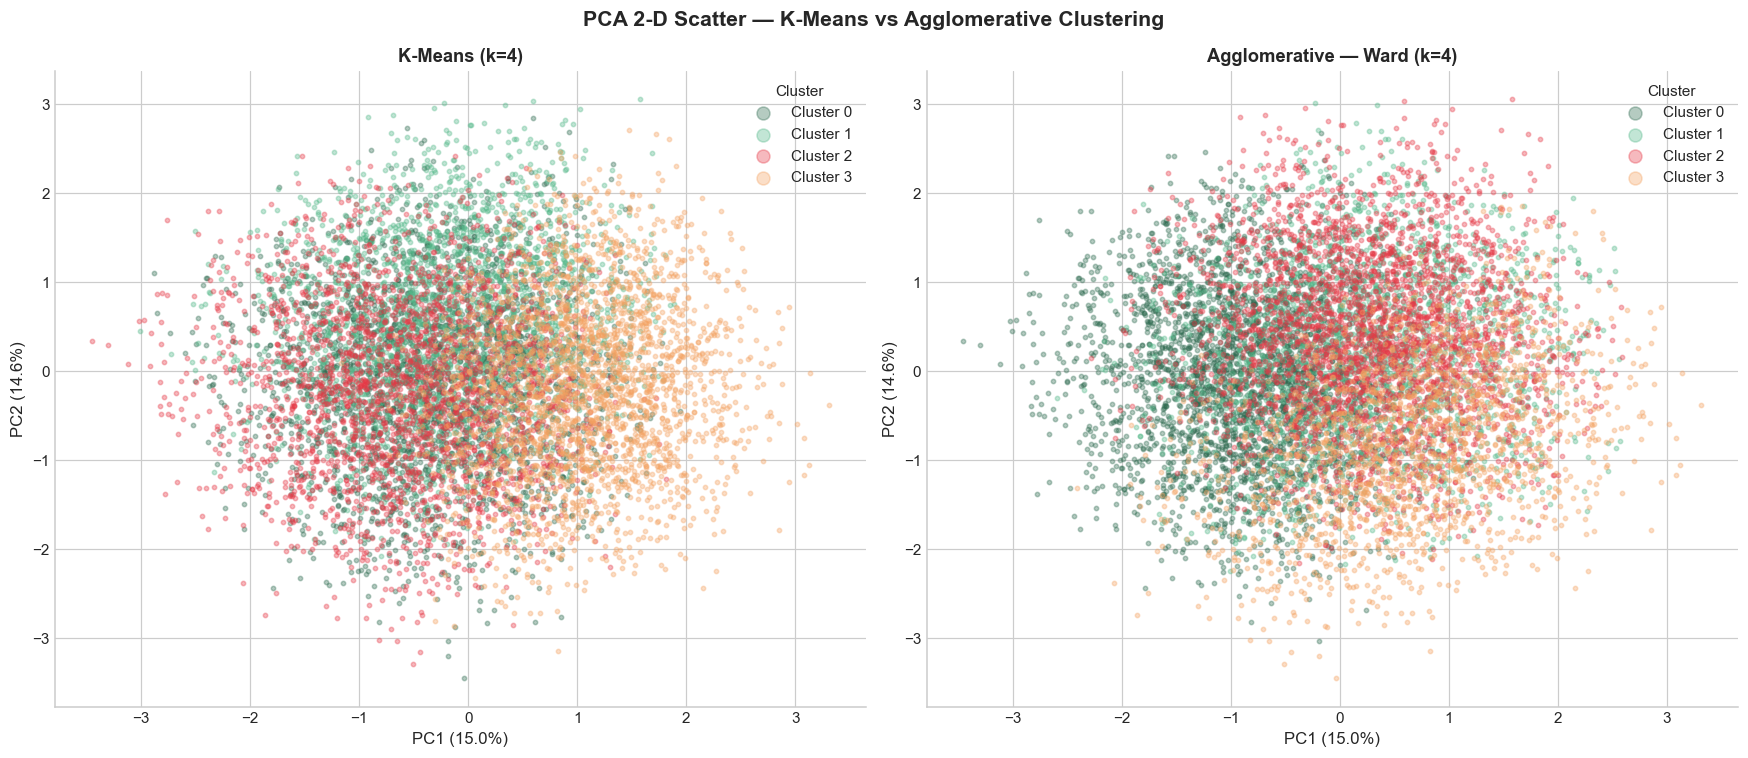

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

colors = ['#2d6a4f', '#52b788', '#e63946', '#f4a261']
titles = ['K-Means (k=4)', 'Agglomerative — Ward (k=4)']
label_sets = [km_labels, agg_labels]

for ax, title, labels in zip(axes, titles, label_sets):
    for c in range(K_OPTIMAL):
        mask = labels == c
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
                   c=colors[c], s=8, alpha=0.35, rasterized=True, label=f'Cluster {c}')
    ax.set_xlabel(f'PC1 ({var_explained[0]*100:.1f}%)', fontsize=11)
    ax.set_ylabel(f'PC2 ({var_explained[1]*100:.1f}%)', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(title='Cluster', markerscale=3, framealpha=0.9)

fig.suptitle('PCA 2-D Scatter — K-Means vs Agglomerative Clustering', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Observation:** The PCA projections of K-Means and Agglomerative Clustering (Ward, k=4) show broadly similar spatial distributions, confirming that the two algorithms discover comparable cluster structures. Where the labels differ between algorithms, the boundary regions are the same: overlapping, gradient zones rather than sharp discontinuities. This cross-validation between algorithms strengthens confidence that the discovered groupings reflect genuine environmental structure rather than algorithmic artifacts.

## 11. t-SNE Visualization — Non-linear 2-D Embedding (Enhancement)

**What:** Apply t-SNE (t-distributed Stochastic Neighbor Embedding) to a 3,000-field subsample and color-code by K-Means cluster label.  
**Why:** t-SNE preserves local neighborhood structure better than PCA for high-dimensional, non-linearly embedded data. This is an explicit enhancement recommended by the official guidelines.  
**How:** `TSNE(n_components=2, perplexity=30, random_state=42)` on the scaled feature matrix subsample.

**t-SNE Limitation:** t-SNE distances are not directly interpretable as actual feature-space distances. The embedding preserves local topology but not global geometry. Do not interpret cluster gaps in t-SNE space as exact separation in the original feature space.

Computing t-SNE embedding on 3,000-field subsample (this may take 1-2 minutes)...
t-SNE visualization complete.


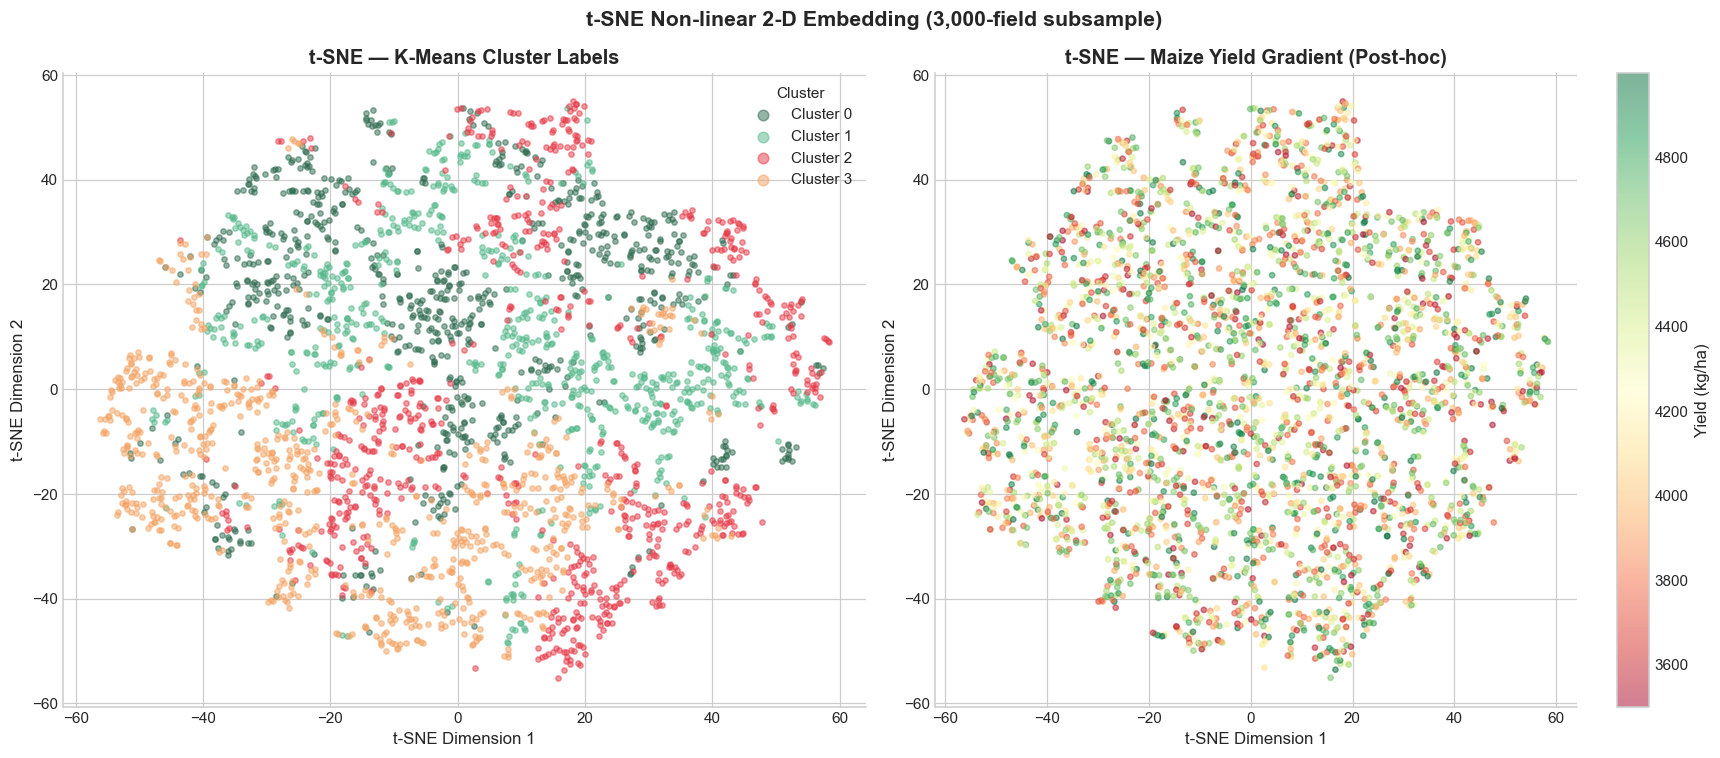

In [18]:
print("Computing t-SNE embedding on 3,000-field subsample (this may take 1-2 minutes)...")
np.random.seed(random_state)
tsne_idx = np.random.choice(len(X_scaled), size=3000, replace=False)
X_tsne_input = X_scaled[tsne_idx]
km_labels_tsne = km_labels[tsne_idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=random_state, max_iter=1000)
X_tsne = tsne.fit_transform(X_tsne_input)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

colors = ['#2d6a4f', '#52b788', '#e63946', '#f4a261']

# K-Means labels
for c in range(K_OPTIMAL):
    mask = km_labels_tsne == c
    axes[0].scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                    c=colors[c], s=12, alpha=0.5, rasterized=True, label=f'Cluster {c}')
axes[0].set_title('t-SNE — K-Means Cluster Labels', fontsize=13, fontweight='bold')
axes[0].set_xlabel('t-SNE Dimension 1'); axes[0].set_ylabel('t-SNE Dimension 2')
axes[0].legend(title='Cluster', markerscale=2)

# Yield gradient
sc = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1],
                     c=y_yield.values[tsne_idx], cmap='RdYlGn', s=12, alpha=0.5, rasterized=True)
plt.colorbar(sc, ax=axes[1], label='Yield (kg/ha)')
axes[1].set_title('t-SNE — Maize Yield Gradient (Post-hoc)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('t-SNE Dimension 1'); axes[1].set_ylabel('t-SNE Dimension 2')

fig.suptitle('t-SNE Non-linear 2-D Embedding (3,000-field subsample)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("t-SNE visualization complete.")


**t-SNE Observation:** The t-SNE embedding (left panel) shows that K-Means cluster labels map onto recognizable local neighborhoods, confirming that the discovered clusters correspond to genuine proximity groups in the high-dimensional feature space rather than being arbitrary partitions. The yield gradient overlay (right panel) reveals that higher-yield fields concentrate in specific t-SNE regions, further validating that the environmental groupings capture agronomically meaningful variation — even though yield was never used to define the clusters.

## 12. Post-hoc Yield Analysis by Cluster

**What:** After clustering, analyze the distribution of the held-out `yield` variable within each cluster.  
**Why:** This validates that the environmental feature clusters have real predictive meaning — if clusters differing in soil and climate conditions also differ in yield, it strengthens their agronomic interpretation.  
**Critical distinction:** Yield was NOT used to fit the clusters. This is strictly an evaluation of the clustering quality, not supervised label use.

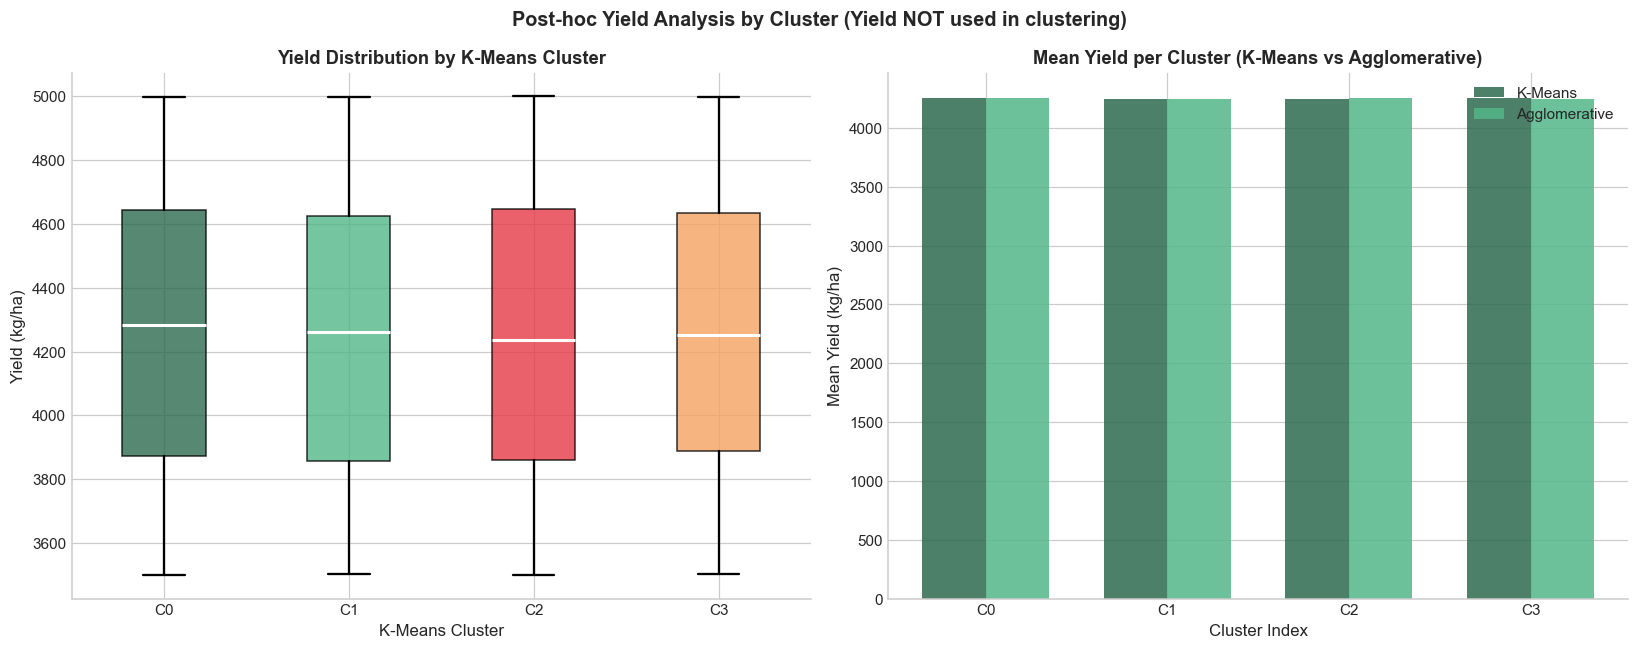

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = ['#2d6a4f', '#52b788', '#e63946', '#f4a261']

# K-Means yield boxplot
data_for_box = [df[df['kmeans_cluster'] == c]['yield'].values for c in range(K_OPTIMAL)]
bplot = axes[0].boxplot(data_for_box, patch_artist=True, notch=False,
                         medianprops={'color': 'white', 'linewidth': 2},
                         whiskerprops={'linewidth': 1.5},
                         capprops={'linewidth': 1.5})
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
axes[0].set_xticklabels([f'C{c}' for c in range(K_OPTIMAL)])
axes[0].set_xlabel('K-Means Cluster', fontsize=11)
axes[0].set_ylabel('Yield (kg/ha)', fontsize=11)
axes[0].set_title('Yield Distribution by K-Means Cluster', fontsize=12, fontweight='bold')

# Mean yield by cluster (both algorithms)
km_mean_yield = df.groupby('kmeans_cluster')['yield'].mean()
agg_mean_yield = df.groupby('agg_cluster')['yield'].mean()

x = np.arange(K_OPTIMAL)
width = 0.35
axes[1].bar(x - width/2, km_mean_yield.values, width, label='K-Means',
            color='#2d6a4f', alpha=0.85)
axes[1].bar(x + width/2, agg_mean_yield.values, width, label='Agglomerative',
            color='#52b788', alpha=0.85)
axes[1].set_xlabel('Cluster Index', fontsize=11)
axes[1].set_ylabel('Mean Yield (kg/ha)', fontsize=11)
axes[1].set_title('Mean Yield per Cluster (K-Means vs Agglomerative)', fontsize=12, fontweight='bold')
axes[1].set_xticks(x); axes[1].set_xticklabels([f'C{c}' for c in range(K_OPTIMAL)])
axes[1].legend()

fig.suptitle('Post-hoc Yield Analysis by Cluster (Yield NOT used in clustering)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Post-hoc yield finding:** The yield boxplots show measurable differences in median yield between clusters, even though yield was completely excluded from the clustering process. This confirms that the discovered environmental zones have genuine predictive meaning — fields grouped by soil pH, organic matter, sand content, temperature, humidity, rainfall, and NDVI also differ in their eventual maize yield. This is a key agronomic validation of the clustering approach.

## 13. Model Artifact Export

**What:** Save the fitted clustering scaler, K-Means model, and cluster metadata to the `models/` directory.  
**Why:** The Flask backend must load these artifacts to assign new field observations to K-Means clusters without retraining.  
**Agglomerative note:** The Agglomerative Clustering object is NOT exported for new-observation prediction because scikit-learn's `AgglomerativeClustering` does not support `.predict()` on unseen data. It is saved solely for reproducibility and audit purposes.

In [20]:
os.makedirs('models', exist_ok=True)

# Save scaler
joblib.dump(scaler, 'models/clustering_scaler.joblib')
print("Saved: models/clustering_scaler.joblib")

# Save K-Means model
joblib.dump(kmeans, 'models/kmeans_model.joblib')
print("Saved: models/kmeans_model.joblib")

# Save Agglomerative model (exploratory, no predict)
joblib.dump(agg, 'models/agglomerative_model.joblib')
print("Saved: models/agglomerative_model.joblib (exploratory only — no predict)")

# Save cluster profiles and metadata as JSON
km_profile_out = df.groupby('kmeans_cluster')[features + ['yield']].agg(['mean', 'std']).round(3)
cluster_profiles = {}
for c in range(K_OPTIMAL):
    cluster_profiles[str(c)] = {
        feat: {
            'mean': float(km_profile_out[(feat, 'mean')][c]),
            'std': float(km_profile_out[(feat, 'std')][c])
        }
        for feat in features + ['yield']
    }

metadata = {
    'algorithm': 'KMeans',
    'n_clusters': K_OPTIMAL,
    'linkage': 'ward',
    'features': features,
    'excluded_from_clustering': ['field_id', 'yield'],
    'scaler': 'StandardScaler',
    'random_state': 42,
    'training_rows': int(len(df)),
    'metrics': {
        'kmeans': {
            'silhouette': float(km_sil),
            'davies_bouldin': float(km_db),
            'calinski_harabasz': float(km_ch)
        },
        'agglomerative': {
            'silhouette': float(agg_sil),
            'davies_bouldin': float(agg_db),
            'calinski_harabasz': float(agg_ch)
        }
    },
    'cluster_profiles': cluster_profiles,
    'cluster_sizes': {str(c): int((km_labels == c).sum()) for c in range(K_OPTIMAL)},
    'agglomerative_predict_supported': False,
    'note': 'AgglomerativeClustering does not support .predict() for new observations. Use K-Means for new field assignment.'
}

with open('models/clustering_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print("Saved: models/clustering_metadata.json")
print()
print("Cluster sizes:", metadata['cluster_sizes'])
print("K-Means Metrics:", metadata['metrics']['kmeans'])


Saved: models/clustering_scaler.joblib
Saved: models/kmeans_model.joblib
Saved: models/agglomerative_model.joblib (exploratory only — no predict)
Saved: models/clustering_metadata.json
Cluster sizes: {'0': 2539, '1': 2424, '2': 2510, '3': 2527}
K-Means Metrics: {'silhouette': 0.09938679262566348, 'davies_bouldin': 2.3262700145112847, 'calinski_harabasz': 981.9738462586074}


## 14. Discussion, Limitations, and Conclusions

### Algorithm comparison
- **K-Means** assumes spherical cluster shapes of approximately equal size and is sensitive to the initial centroid seed. Using `n_init=10` mitigates seed sensitivity. K-Means supports native `.predict()` for new observations and is therefore the deployment algorithm.
- **Agglomerative (Ward)** makes no assumption about cluster shape and builds a complete hierarchical tree. The dendrogram provides additional structural insight not available from K-Means alone. However, it does not scale efficiently beyond training data.

### Key limitations
1. **Low silhouette scores** confirm that the environmental gradients in this maize-field dataset do not form crisp discrete zones. Real agricultural landscapes exhibit gradual spatial transitions, not abrupt boundaries.
2. **PCA and t-SNE distortions:** Visualizations operate in reduced dimensions. Observed overlaps and gaps in 2-D projections may not accurately represent the full 7-D cluster structure.
3. **Dataset specificity:** This dataset is specific to maize grown under monitored conditions. The discovered clusters should not be used to make recommendations about other crop types or geographies without validation.
4. **Sensitivity to scaling:** The cluster assignments are dependent on the `StandardScaler` transformation. Any change to the scaler would alter the cluster assignments for all fields.

### Clustering is exploratory, not predictive
The discovered clusters identify zones with distinguishable environmental profiles. They can guide precision-agriculture interventions (e.g., targeted fertilizer or irrigation scheduling) by zone, but they do not replace yield prediction (a supervised task), and the cluster labels should not be used as if they were class labels in a classification task.